In [1]:
!pip install scikit-learn

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

In [3]:
df = pd.DataFrame([[153,63], [174,81], [136,56],
                    [186,91], [128,47], [136,57],
                    [179,76], [163,72], [131,48]])


df.colums = ["x", "y"]


C:\Users\fieqi\AppData\Local\Temp\ipykernel_22016\2943954136.py:6: UserWarning: Pandas doesn't allow columns to be created via a new attribute name - see https://pandas.pydata.org/pandas-docs/stable/indexing.html#attribute-access
  df.colums = ["x", "y"]


In [4]:
df.corr()

,0,1
0,1.000000,0.976058
1,0.976058,1.000000


In [5]:
import numpy as np
from sklearn.model_selection import train_test_split

# ambil kolom pertama sebagai x, kolom kedua sebagai y (berdasarkan posisi)
X = df.iloc[:, 0].values[:, np.newaxis]   # shape (n, 1)
y = df.iloc[:, 1].values                  # shape (n,)

# membagi data: 80% latih, 20% uji
x_train, x_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(x_train.shape, x_test.shape)
x_train

(7, 1) (2, 1)


array([[136],
       [153],
       [131],
       [136],
       [128],
       [186],
       [179]])

In [6]:
y_train

array([57, 63, 48, 56, 47, 91, 76])

In [7]:
#model training 
im = LinearRegression()
im.fit(x_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[0.65]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-35.04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[58.16]


In [8]:
#Membuat  Prediksi

x_test = [[170], [160], [180], [171], [150]]
p = im.predict(x_test)
p

array([75.69235642, 69.17842061, 82.20629223, 76.34375   , 62.6644848 ])

In [9]:
# koefisien regresi & intersep

print("Coefficient :", im.coef_)
print("Intercept :", im.intercept_)

Coefficient : [0.65139358]
Intercept : -35.044552364864856


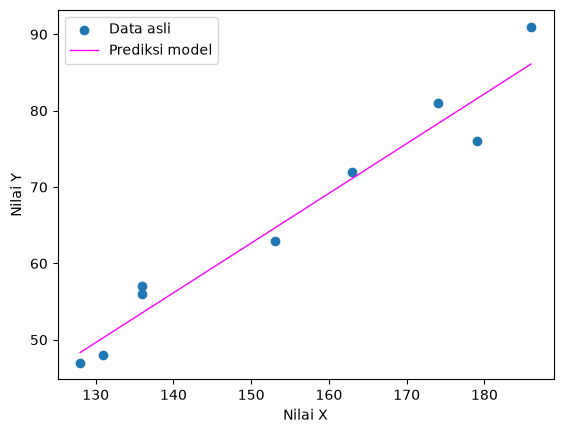

In [10]:
import numpy as np
import matplotlib.pyplot as plt

# prediksi untuk seluruh data (X dan y dari langkah pembagian data)
pb = im.predict(X)

# urutkan berdasarkan x supaya garis tidak zig-zag
urut = np.argsort(X[:, 0])

plt.scatter(X[:, 0], y, label='Data asli')
plt.plot(X[urut, 0], pb[urut], color='magenta', linewidth=1, label='Prediksi model')
plt.xlabel('Nilai X')
plt.ylabel('Nilai Y')
plt.legend()
plt.show()

In [11]:
df = pd.read_csv("botak.csv")
df

,umur,jenis_kelamin,pekerjaan,provinsi,gaji,is_menikah,is_keturunan,berat,tinggi,sampo,is_merokok,pendidikan,botak_prob
0,42.0,Laki-laki,PNS,Padang,7.864005e+06,0,0.0,61.928685,152.174164,Deadbuoy,1,S1,0.487655
1,33.0,Laki-laki,Pegawai swasta,Palangkaraya,6.492662e+06,0,0.0,49.374507,152.822969,Moonsilk,1,SMA,0.297270
2,59.0,Laki-laki,Freelance,Serang,8.086303e+06,1,0.0,59.072807,159.911047,Merpati,1,S1,0.467848
3,38.0,Laki-laki,Pegawai swasta,Gorontalo,1.147321e+07,0,1.0,68.338014,162.558997,Moonsilk,0,S1,0.616418
4,33.0,Perempuan,Freelance,Tanjungselor,1.475942e+07,0,0.0,53.769996,154.579510,Pantone,1,S2,0.115439
...,...,...,...,...,...,...,...,...,...,...,...,...,...
7986,31.0,Laki-laki,Pegawai swasta,Padang,2.911963e+07,0,0.0,83.272785,176.020857,Merpati,0,SMA,0.241525
7987,40.0,Perempuan,Pegawai swasta,Banjarmasin,8.955173e+06,0,0.0,61.634474,161.780773,Deadbuoy,0,S1,0.140971
7988,43.0,Perempuan,PNS,Mataram,4.022652e+06,0,0.0,50.525031,152.461656,Shoulder & Head,1,S1,0.364456
7989,29.0,Laki-laki,Pegawai swasta,Serang,5.801753e+06,0,0.0,47.175270,152.749709,NaN,1,SMA,0.248910


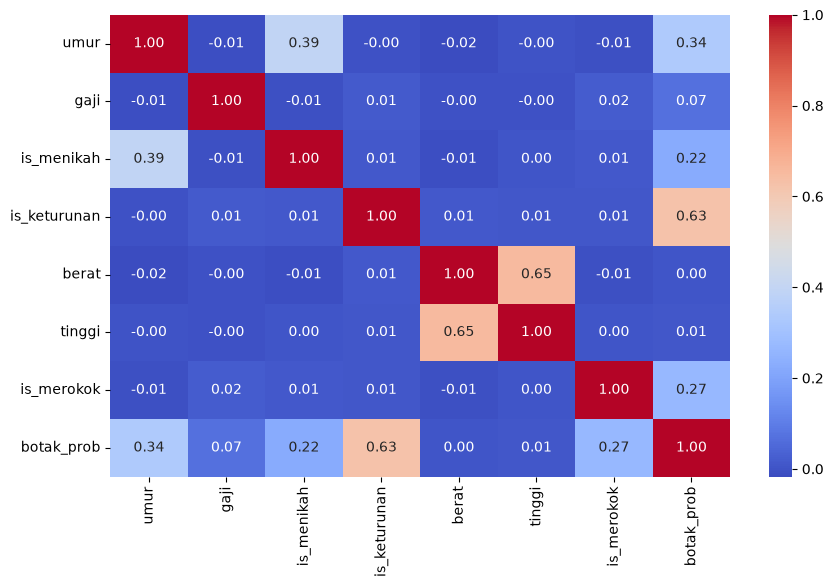

In [16]:
import seaborn as sns
import matplotlib.pyplot as plt

num_df = df.select_dtypes(include='number')

plt.figure(figsize=(10, 6))
sns.heatmap(num_df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.show()

In [19]:
db_clean = df.dropna(subset=["umur", "tinggi", "berat", "botak_prob"])

x = db_clean[["umur", "gaji", "tinggi", "berat"]]
y = db_clean["botak_prob"]

In [21]:
import numpy as np
from sklearn.model_selection import train_test_split as tts

X = df.iloc[:, 0].values[:, np.newaxis]
y = df.iloc[:, 1].values

x_train, x_test, y_train, y_test = tts(X, y, test_size=0.2, random_state=0)

print(x_train.shape, x_test.shape)

(6392, 1) (1599, 1)


Kolom numerik: ['umur', 'gaji', 'is_menikah', 'is_keturunan', 'berat', 'tinggi', 'is_merokok', 'botak_prob']
x: is_menikah | y: is_keturunan
Baris setelah dibersihkan: 7976 dari 7991
Slope    : 0.01782096662882175
Intercept: 0.1918564527260179
MAE      : 0.3132624347362531
RMSE     : 0.397385650256159
R2 uji   : 0.0001701690646352949


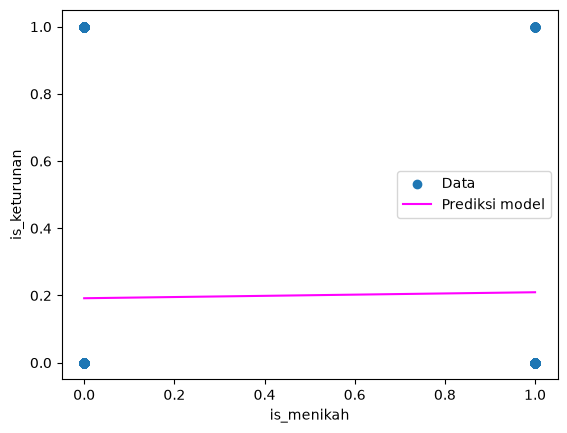

In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# ambil kolom numerik saja, buang Id kalau ada
num = df.select_dtypes(include='number')
num = num.drop(columns=[c for c in num.columns if c.lower() == 'id'])
print("Kolom numerik:", num.columns.tolist())

# kolom numerik ke-3 = petal length (x), ke-4 = petal width (y)
kol_x, kol_y = num.columns[2], num.columns[3]
print("x:", kol_x, "| y:", kol_y)

data = num[[kol_x, kol_y]].dropna()
print("Baris setelah dibersihkan:", len(data), "dari", len(df))

X = data[[kol_x]].values
y = data[kol_y].values

xr_train, xr_test, yr_train, yr_test = train_test_split(X, y, test_size=0.25, random_state=0)

model = LinearRegression()
model.fit(xr_train, yr_train)

yr_pred = model.predict(xr_test)
print("Slope    :", model.coef_[0])
print("Intercept:", model.intercept_)
print("MAE      :", mean_absolute_error(yr_test, yr_pred))
print("RMSE     :", np.sqrt(mean_squared_error(yr_test, yr_pred)))
print("R2 uji   :", r2_score(yr_test, yr_pred))

urut = np.argsort(X[:, 0])
plt.scatter(X[:, 0], y, label='Data')
plt.plot(X[urut, 0], model.predict(X)[urut], color='magenta', label='Prediksi model')
plt.xlabel(kol_x)
plt.ylabel(kol_y)
plt.legend()
plt.show()

In [32]:
# prediksi
y_pred = model.predict(x_test)

In [37]:
#evaluasi
from sklearn.metrics import mean_squared_error, r2_score

print("coefficient :", model.coef_)
print("intercept :", model.intercept_)
print("MSE :", mean_squared_error(y_test, y_pred))
print("R2 Score :", r2_score(y_test, y_pred))

AttributeError: 'LinearRegression' object has no attribute 'coef_'

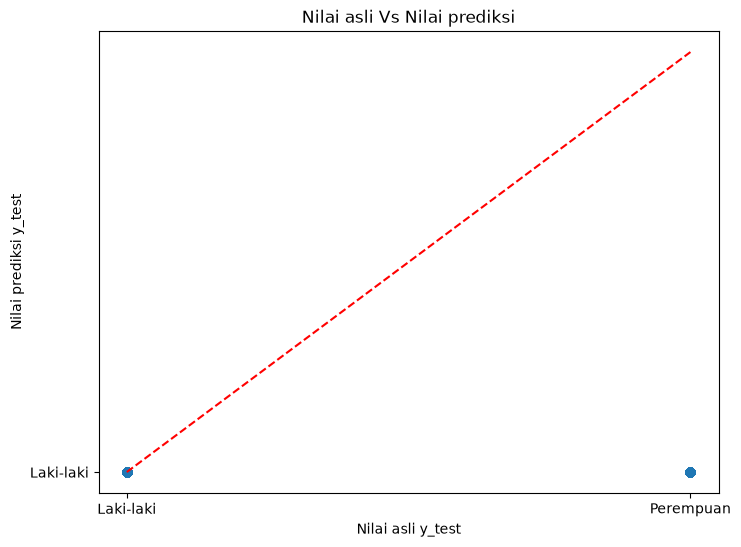

In [38]:
#visualisasi model

plt.figure(figsize=(8,6))
plt.scatter(y_test, y_pred, alpha = 0.5)
plt.xlabel("Nilai asli y_test")
plt.ylabel("Nilai prediksi y_test")
plt.title("Nilai asli Vs Nilai prediksi")
plt.plot([0,1],[0,1],'r--')
plt.show()